# Growth Rate


## Setup

Configuration and data loading

In [ ]:
## SHARED CONFIG ##

# Reload configs on each run.
import importlib

import analyse_pr_config
importlib.reload(analyse_pr_config)
from analyse_pr_config import (CONTAMINATED_BLANK_PLATE, EXP_GROWTH_PHASE_THRESHOLD, FIGURE_DPI,
                               PDF_DPI, POLY_EDGE_EXCLUDE, POLY_ORDER, REPLICATES,
                               SG_EDGE_EXCLUDE, SG_POLYORDER, SG_WINDOW, TAGS, WELLS,
                               biomass_and_floor, blank_series, load_plate_series, smooth)


from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from bioutils.microplate import (
    well_label_to_coords_384,
    well_coords_to_label_384,
    get_adjacent_wells,
    get_circuit_wells,
)
from bioutils import transform


## PLOTTING ##

plt.rcParams["figure.dpi"] = FIGURE_DPI 
plt.rcParams["savefig.dpi"] = FIGURE_DPI

## OUTPUT ##

# generated data
OUT_DIR = Path("out")
OUT_DIR.mkdir(exist_ok=True)

# 92-page renders take ~10 min; off by default
GENERATE_PDF = True

## CIRCUITS ##

# Circuit in inline figures
CIRCUIT = 75



In [2]:
# Load data
od_raw, fl_raw, t_minutes = load_plate_series()

for tag in TAGS:
    print(f"{tag}: plate shape={od_raw[tag].shape}, runtime={t_minutes[tag][-1]:.0f} min")


Rep1: plate shape=(16, 24, 41), runtime=480 min
Rep2: plate shape=(16, 24, 41), runtime=480 min
Rep3: plate shape=(16, 24, 41), runtime=480 min


## Blank OD Distribution


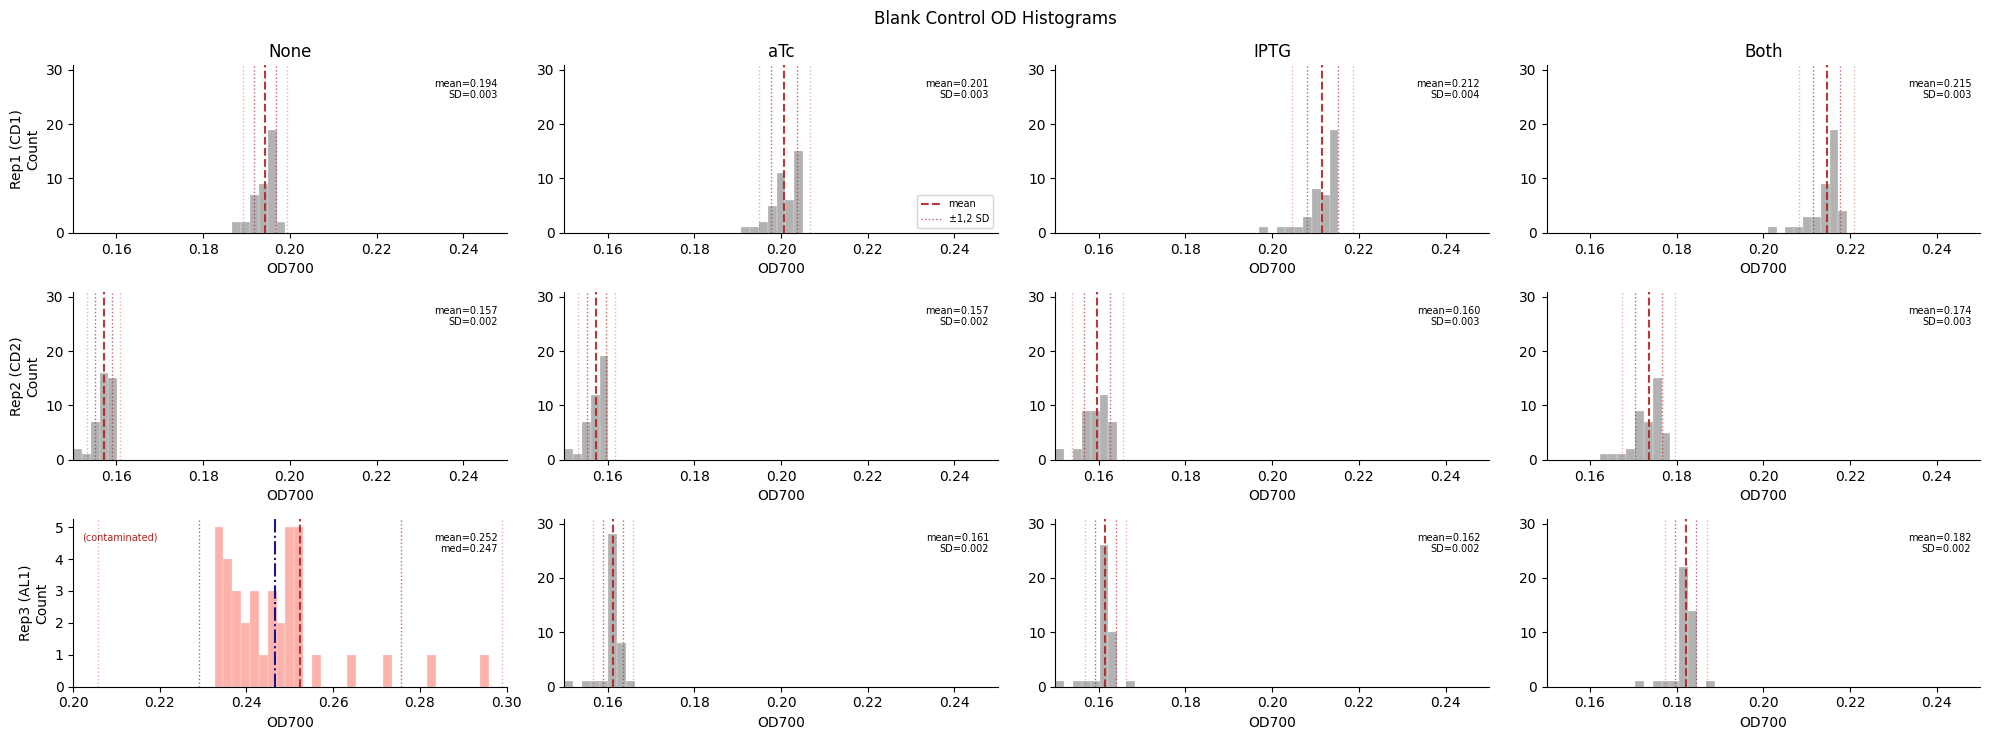

In [3]:
# Blank OD histogram per (replicate, condition)
BLANK_HISTOGRAM_BINS = np.linspace(0.15, 0.25, 50)
BLANK_EXCLUDED_HISTOGRAM_BINS = np.linspace(0.2, 0.3, 50)

fig, axes = plt.subplots(len(REPLICATES), 4, figsize=(20, 7.5))
shared_axes, ymax = [], 0
for rep_i, rep in enumerate(REPLICATES):
    tag = rep["tag"]
    rows, cols = zip(*rep["wells"]["blank"])
    # [4 cond, n_t]
    blank = smooth(od_raw[tag][list(rows), list(cols), :])

    for well in range(4):
        ax = axes[rep_i, well]
        vals = blank[well][np.isfinite(blank[well])]

        # Contaminated blank is plate-specific
        is_excluded = rep["label"] == CONTAMINATED_BLANK_PLATE and well == 0
        
        is_legend_panel = rep_i == 0 and well == 1
        mean, median, sd = vals.mean(), np.median(vals), vals.std()

        bins = BLANK_EXCLUDED_HISTOGRAM_BINS if is_excluded else BLANK_HISTOGRAM_BINS
        counts, _, _ = ax.hist(vals, bins=bins, color=("salmon" if is_excluded else "gray"),
                               alpha=0.6, edgecolor="white", linewidth=0.3)

        ax.axvline(mean, color="firebrick", ls="--", lw=1.5, alpha=0.9,
                   label="mean" if is_legend_panel else None)
        
        if is_excluded:
            ax.axvline(median, color="navy", ls="-.", lw=1.5, alpha=0.9,
                       label="median" if is_legend_panel else None)
        
        for i, (n_sd, alpha) in enumerate([(1, 0.7), (2, 0.35)]):
            ax.axvline(mean - n_sd * sd, color="firebrick", ls=":", lw=1, alpha=alpha,
                       label="±1,2 SD" if is_legend_panel and i == 0 else None)
            ax.axvline(mean + n_sd * sd, color="firebrick", ls=":", lw=1, alpha=alpha)

        stats = f"mean={mean:.3f}\nmed={median:.3f}" if is_excluded else f"mean={mean:.3f}\nSD={sd:.3f}"
        ax.text(0.98, 0.92, stats, transform=ax.transAxes, ha="right", va="top", fontsize=7)

        if is_excluded:
            ax.text(0.02, 0.92, "(contaminated)", transform=ax.transAxes,
                    ha="left", va="top", fontsize=7, color="firebrick")
            ax.set_xlim(0.2, 0.3)
        else:
            shared_axes.append(ax)
            ymax = max(ymax, counts.max())
            ax.set_xlim(0.15, 0.25)

        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)
        ax.set_xlabel("OD700")
        if rep_i == 0:
            ax.set_title(rep["cond_labels"][well])
        if well == 0:
            ax.set_ylabel(f"{tag} ({rep['label']})\nCount")

for ax in shared_axes:
    ax.set_ylim(0, ymax * 1.1)

axes[0, 1].legend(fontsize=7, loc="lower right")
fig.suptitle("Blank Control OD Histograms")
plt.tight_layout()
plt.show()


In [4]:
## CONFIG ##

## DETECTION THRESHOLD ##

# Pooled blank and detection threshold per plate
POOLED_BLANK, DETECTION_THRESHOLD, _ = blank_series(od_raw, fl_raw)


## Exclude OD Below Floor


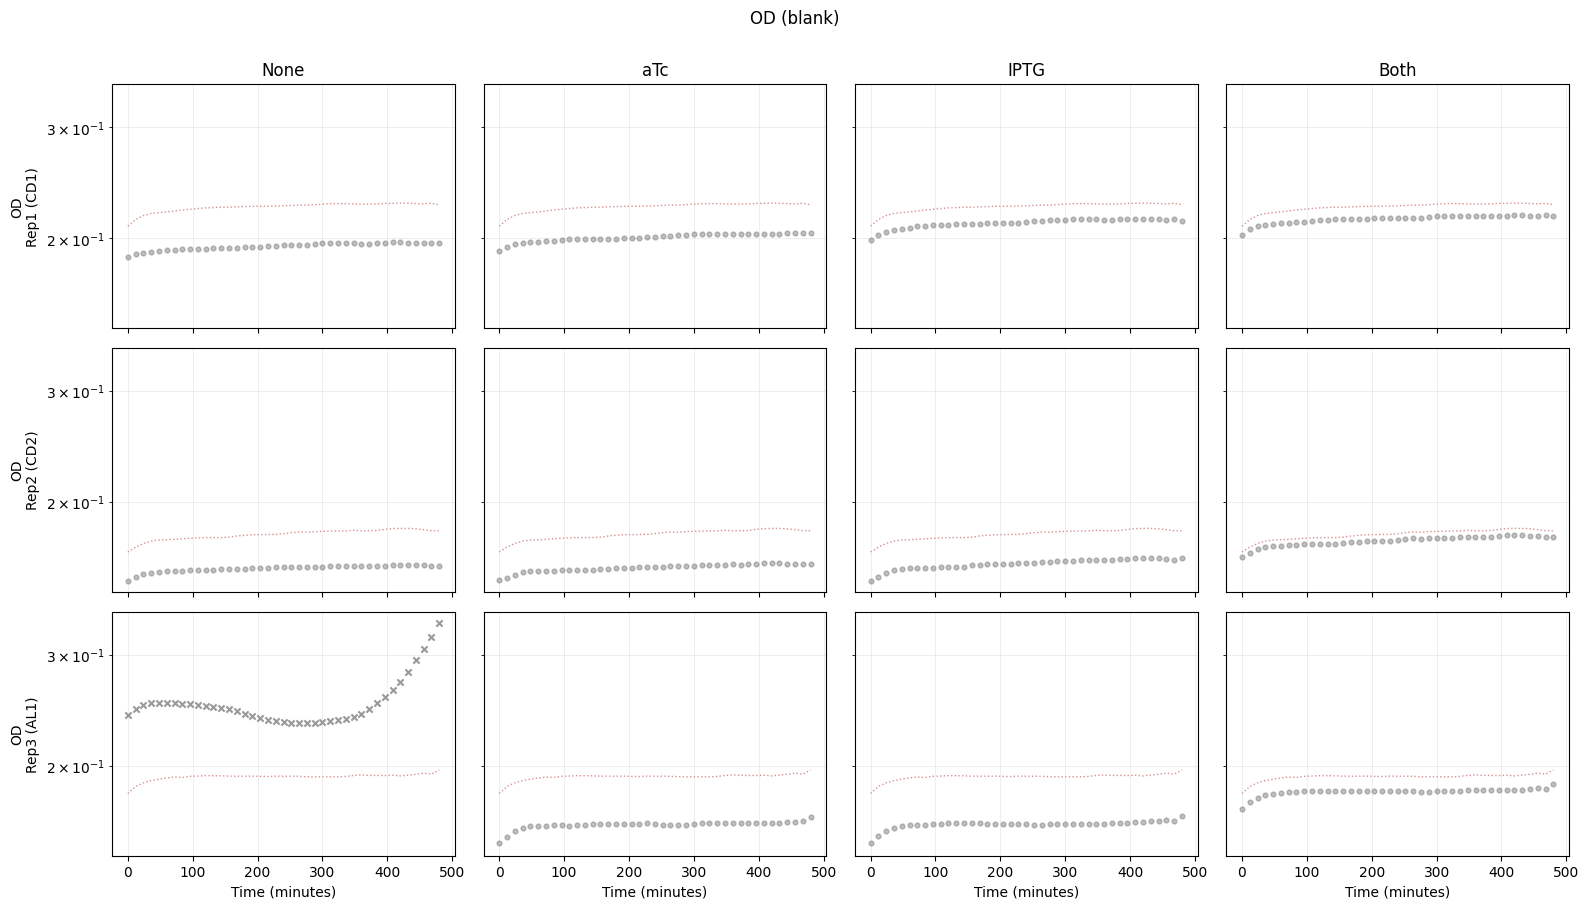

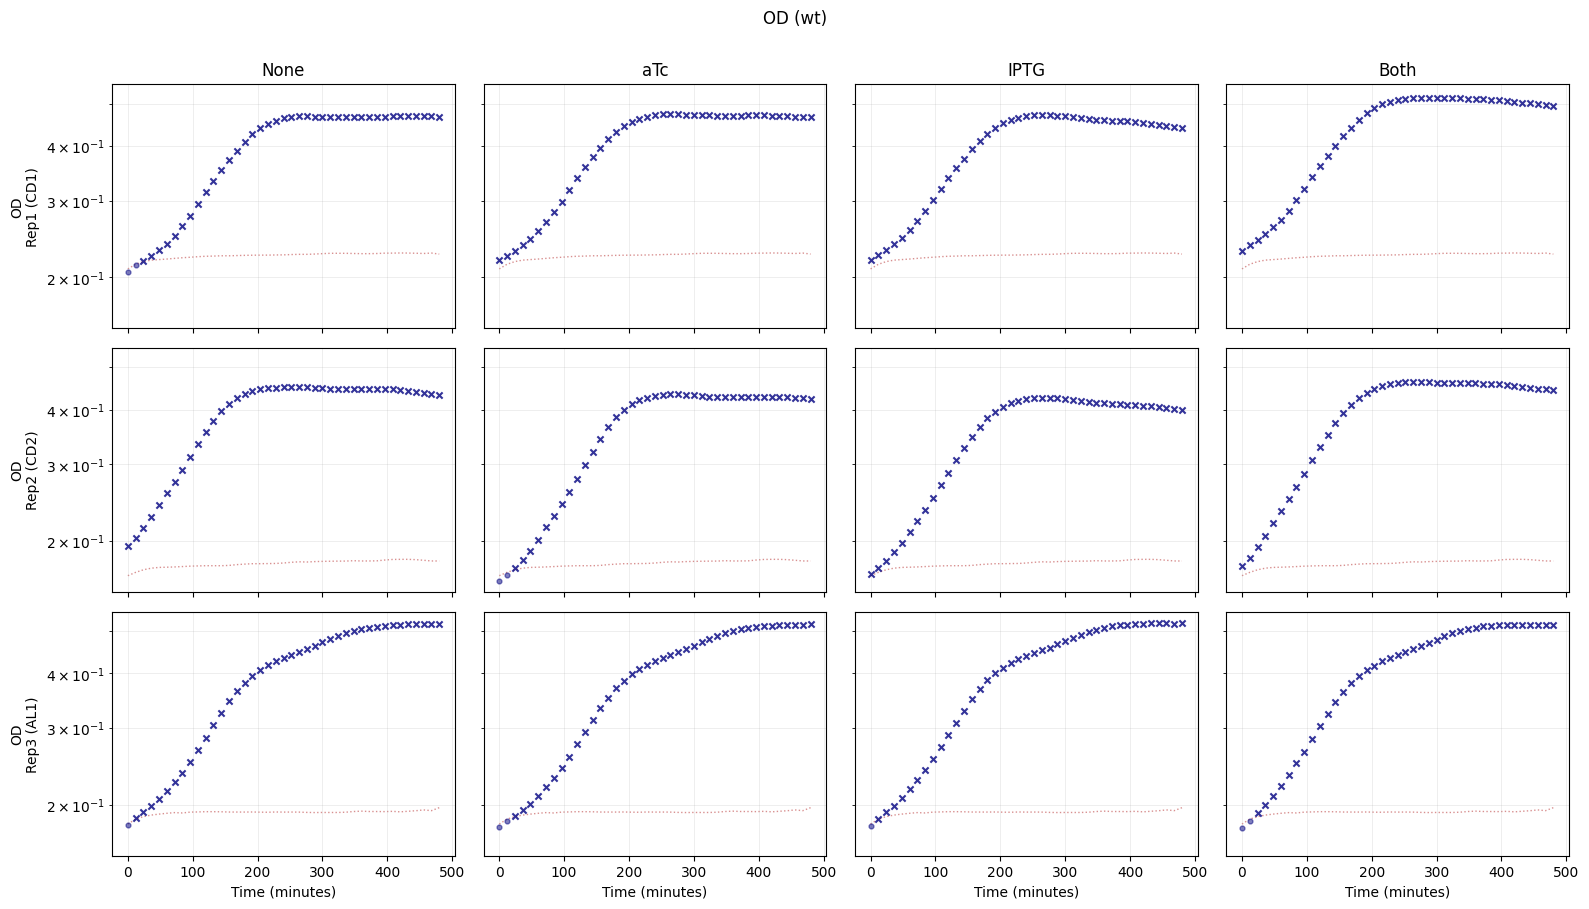

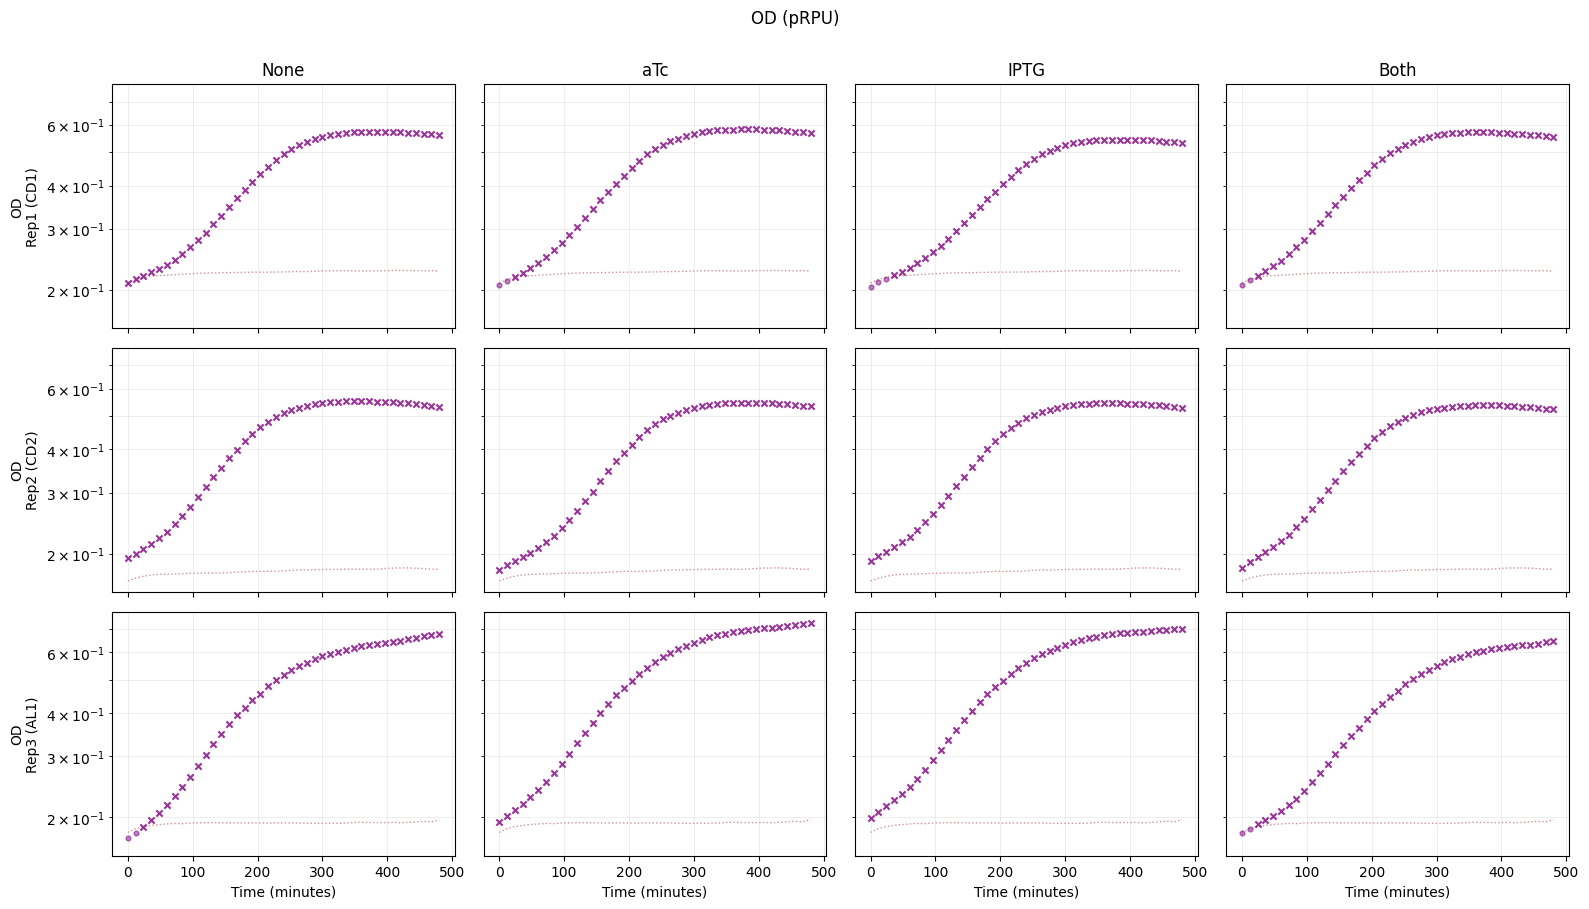

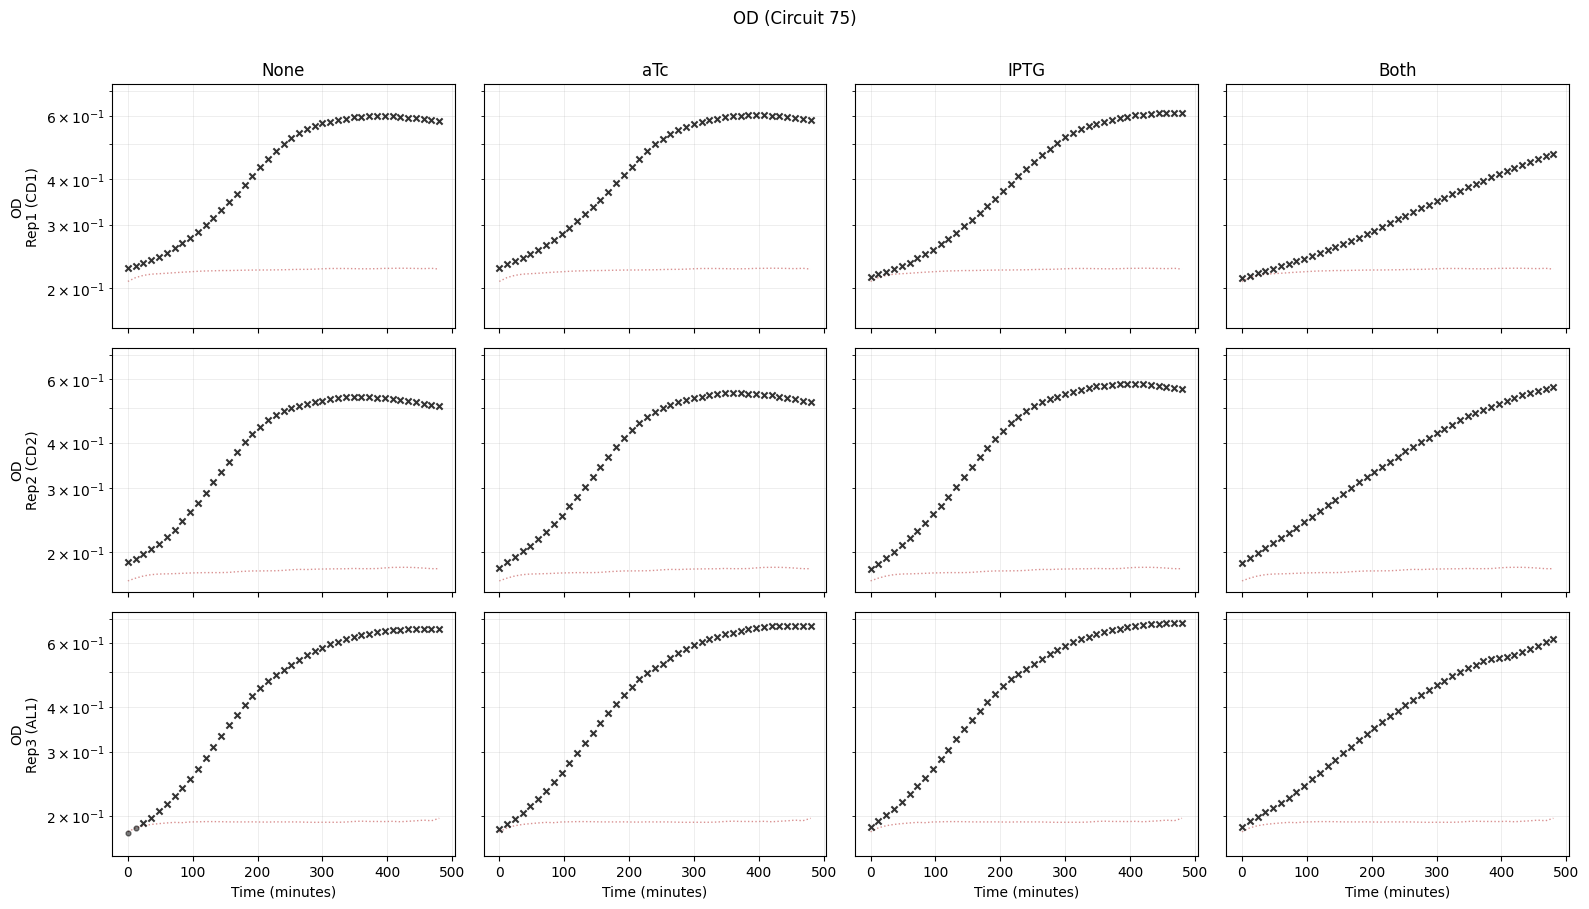

In [5]:
# Smoothed OD with low-saturation exclusion
for group_label, wells, color in [
    ("blank",              WELLS["blank"],              "gray"),
    ("wt",                 WELLS["wt"],                 "navy"),
    ("pRPU",               WELLS["pRPU"],               "purple"),
    (f"Circuit {CIRCUIT}", WELLS["circuits"][CIRCUIT],  "black"),
]:
    fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
    for rep_i, rep in enumerate(REPLICATES):
        tag = rep["tag"]
        rows, cols = zip(*wells)
        raw = smooth(od_raw[tag][list(rows), list(cols), :])
        _, above_all = biomass_and_floor(od_raw[tag][list(rows), list(cols), :],
                                         POOLED_BLANK[tag], DETECTION_THRESHOLD[tag])
        for well in range(4):
            ax = axes[rep_i, well]
            above = above_all[well]

            # included
            ax.scatter(t_minutes[tag][above], raw[well][above],
                       marker="x", color=color, s=20, alpha=0.8, zorder=3)
            # excluded
            ax.scatter(t_minutes[tag][~above], raw[well][~above],
                       marker="o", color=color, s=12, alpha=0.5, zorder=3)

            # Threshold in raw units
            ax.plot(t_minutes[tag], POOLED_BLANK[tag] + DETECTION_THRESHOLD[tag],
                    color="firebrick", ls=":", lw=1, alpha=0.5, zorder=1)

            ax.set_yscale("log")
            ax.grid(True, alpha=0.3, linewidth=0.5, which="both")
            if rep_i == 0:
                ax.set_title(rep["cond_labels"][well])
            if rep_i == len(REPLICATES) - 1:
                ax.set_xlabel("Time (minutes)")
            if well == 0:
                ax.set_ylabel(f"OD\n{tag} ({rep['label']})")

    fig.suptitle(f"OD ({group_label})", y=1.005)
    plt.tight_layout()
    plt.show()


## Raw vs Blank-Corrected


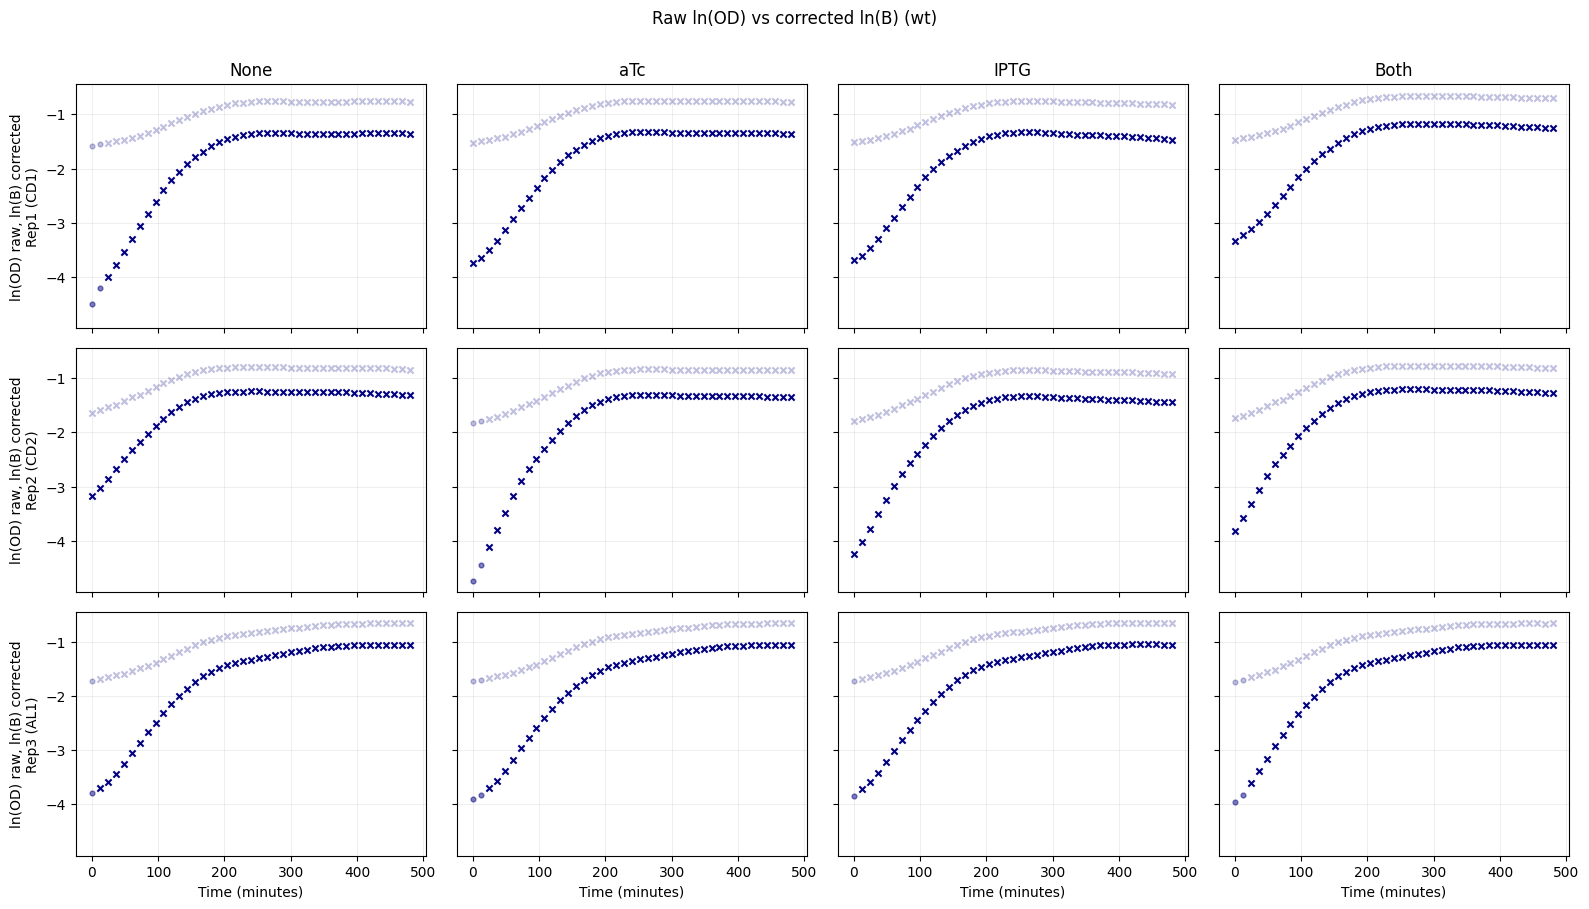

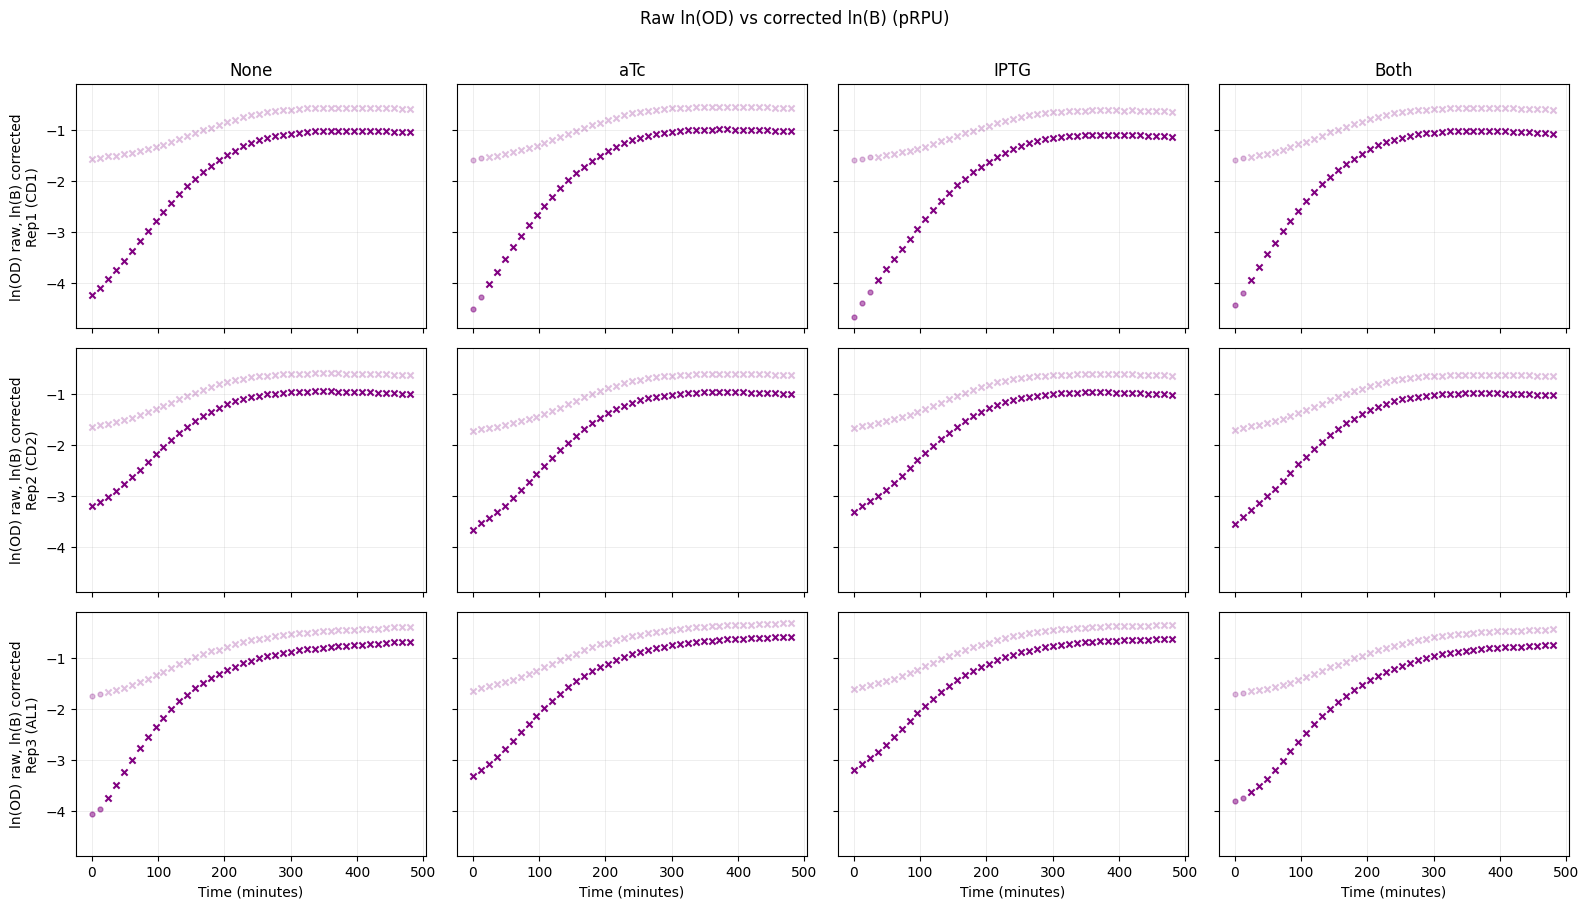

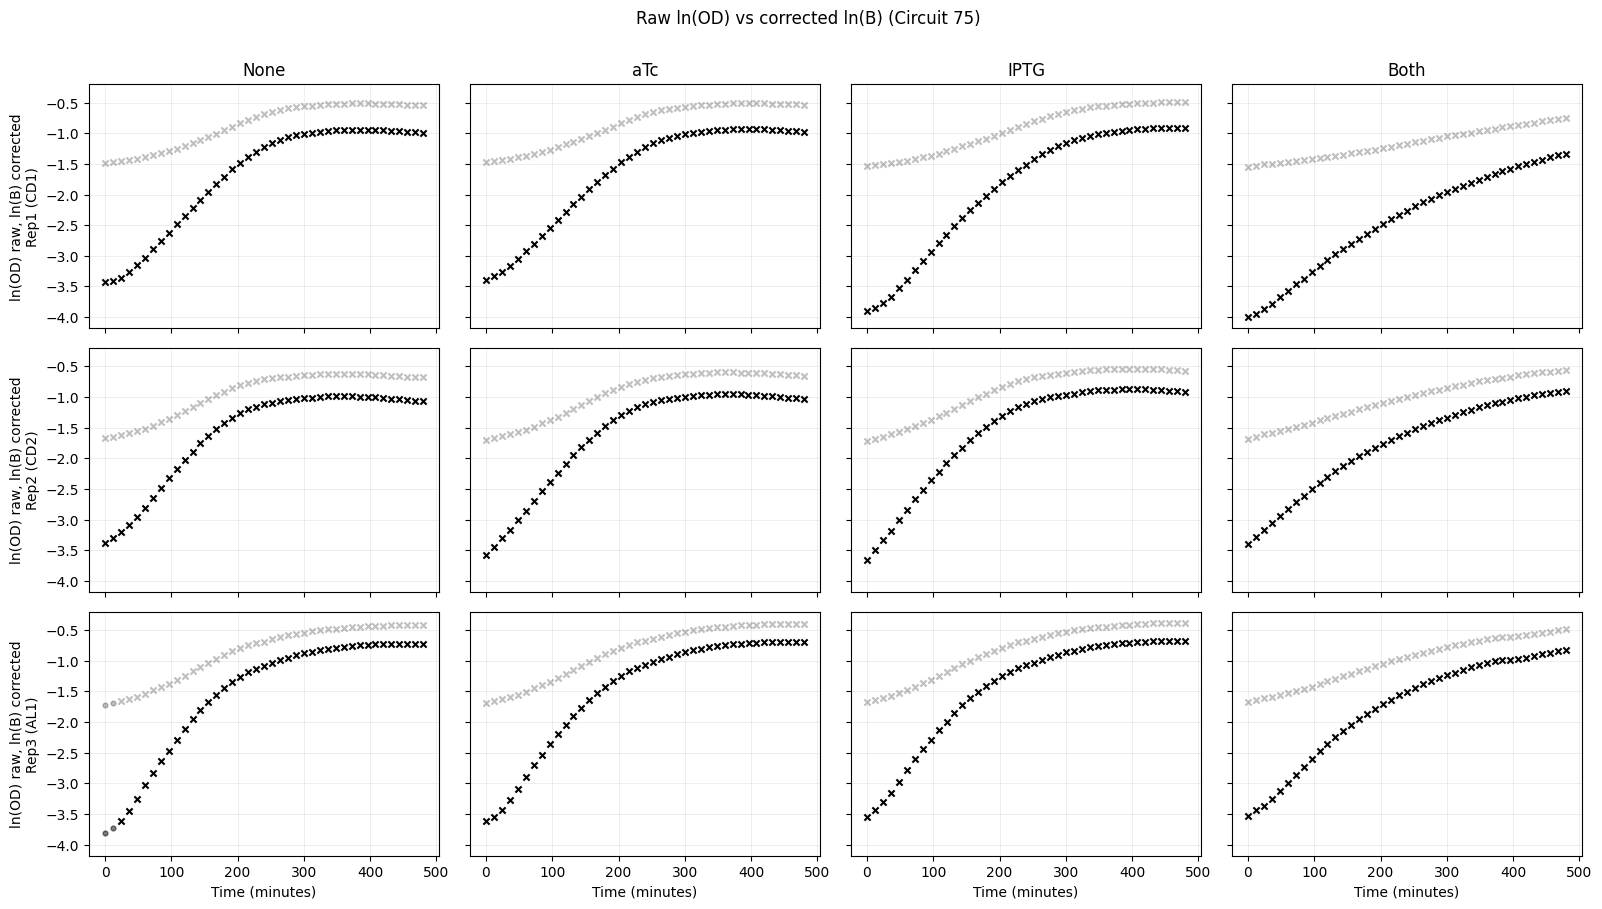

In [6]:
# Raw vs blank-corrected ln(OD)
for group_label, wells, color in [
    ("wt",                 WELLS["wt"],                 "navy"),
    ("pRPU",               WELLS["pRPU"],               "purple"),
    (f"Circuit {CIRCUIT}", WELLS["circuits"][CIRCUIT],  "black"),
]:
    fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)

    for rep_i, rep in enumerate(REPLICATES):
        tag = rep["tag"]
        rows, cols = zip(*wells)
        raw = od_raw[tag][list(rows), list(cols), :].astype(float)
        # Corrected is smoothed, raw is not
        corrected_all, above_all = biomass_and_floor(raw, POOLED_BLANK[tag],
                                                     DETECTION_THRESHOLD[tag])
        corrected = np.where(above_all, corrected_all, np.nan)
        corrected_excluded = np.where(above_all, np.nan, corrected_all)

        for well in range(4):
            ax = axes[rep_i, well]
            above = above_all[well]
            with np.errstate(invalid="ignore"):
                # raw
                ax.scatter(t_minutes[tag][above], np.log(raw[well][above]),
                           marker="x", color=color, s=20, alpha=0.25, zorder=2)
                ax.scatter(t_minutes[tag][~above], np.log(raw[well][~above]),
                           marker="o", color=color, s=12, alpha=0.25, zorder=2)
                # blank-corrected
                ax.scatter(t_minutes[tag], np.log(corrected[well]),
                           marker="x", color=color, s=20, alpha=1.0, zorder=3)
                ax.scatter(t_minutes[tag], np.log(corrected_excluded[well]),
                           marker="o", color=color, s=12, alpha=0.5, zorder=3)

            ax.grid(True, alpha=0.3, linewidth=0.5, which="both")
            if rep_i == 0:
                ax.set_title(rep["cond_labels"][well])
            if rep_i == len(REPLICATES) - 1:
                ax.set_xlabel("Time (minutes)")
            if well == 0:
                ax.set_ylabel(f"ln(OD) raw, ln(B) corrected\n{tag} ({rep['label']})")

    fig.suptitle(f"Raw ln(OD) vs corrected ln(B) ({group_label})", y=1.005)
    plt.tight_layout()
    plt.show()


In [7]:
## PIPELINE ##

def peak_growth_rate(well_series):
    """Maximum growth rate for one well; NaN where nothing is finite."""
    return float(np.nanmax(well_series)) if np.isfinite(well_series).any() else np.nan


def exp_growth_window_indices(growth_rate_series):
    """(first, last) index of the exponential-growth window; None where nothing is finite."""
    if not np.isfinite(growth_rate_series).any():
        return None
    return transform.exp_growth_window(
        growth_rate_series, threshold=EXP_GROWTH_PHASE_THRESHOLD)


def window_middle(first_index, last_index):
    """Middle of a window, rounding up."""
    return (first_index + last_index + 1) // 2


def window_mid_index(growth_rate_series):
    """Index halfway through the exponential-growth window; None where nothing is finite."""
    window = exp_growth_window_indices(growth_rate_series)
    return None if window is None else window_middle(*window)


# The pipeline samples window_mid_index directly


# Blank-correct each group, then split its series at the detection floor.

# Every circuit plus the controls
ALL_GROUPS = {
    **{f"Circuit {circuit}": (WELLS["circuits"][circuit], "black") for circuit in range(1, 93)},
    "pRPU": (WELLS["pRPU"], "purple"),
    "pL2":  (WELLS["pL2"],  "orange"),
    "WT":   (WELLS["wt"],   "navy"),
}

# Subset drawn inline: the circuit against its reference
GROUPS = {name: ALL_GROUPS[name] for name in (
    f"Circuit {CIRCUIT}",
    "pRPU",
)}

od_gmf, od_excluded, above_floor = {}, {}, {}
for name, (wells, colour) in ALL_GROUPS.items():
    od_gmf[name], od_excluded[name], above_floor[name] = {}, {}, {}
    for rep in REPLICATES:
        tag = rep["tag"]
        rows, cols = zip(*wells)
        raw = od_raw[tag][list(rows), list(cols), :].astype(float)
        # smoothed, pooled-blank-corrected, and the floor tested on that same series
        corrected, above = biomass_and_floor(raw, POOLED_BLANK[tag], DETECTION_THRESHOLD[tag])
        above_floor[name][tag] = above
        # ln undefined at or below zero
        for cond, timepoint in zip(*np.nonzero(corrected <= 0)):
            print(f"WARNING: well {well_coords_to_label_384(*wells[cond])}, "
                  f"timepoint {t_minutes[tag][timepoint]:.0f} min: background-corrected "
                  f"OD is {corrected[cond, timepoint]:.4f} (<= 0); "
                  f"this measurement will be omitted from all plots")
        od_gmf[name][tag] = np.where(above, corrected, np.nan)
        od_excluded[name][tag] = np.where(above, np.nan, corrected)


In [8]:
def plot_growth_rate(growth_rate, title, ln_od_fit=None):
    """Per-rep 2x4 grid: growth rate (top) and ln(B) (bottom), circuit against pRPU."""
    for rep in REPLICATES:
        tag = rep["tag"]
        fig, axes = plt.subplots(2, 4, figsize=(16, 6), sharex=True)
        for ax in axes[0, 1:]:
            ax.sharey(axes[0, 0])
        for ax in axes[1, 1:]:
            ax.sharey(axes[1, 0])

        for well in range(4):
            condition = rep["cond_labels"][well]
            ax_gr, ax_lod = axes[0, well], axes[1, well]
            for name, (wells, colour) in GROUPS.items():
                # Exponential-growth window
                if np.isfinite(growth_rate[name][tag][well]).any():
                    start_i, end_i = transform.exp_growth_window(
                        growth_rate[name][tag][well], threshold=EXP_GROWTH_PHASE_THRESHOLD)
                    for ax in (ax_gr, ax_lod):
                        ax.axvspan(t_minutes[tag][start_i], t_minutes[tag][end_i],
                                   color=colour, alpha=0.10, zorder=0, linewidth=0)
                        # Sampled point
                        ax.axvline(t_minutes[tag][window_middle(start_i, end_i)], color=colour,
                                   ls="-", lw=1.4, alpha=0.8, zorder=0.5)

                # growth rate
                ax_gr.plot(t_minutes[tag], growth_rate[name][tag][well],
                           color=colour, lw=1.5, label=name)

                # ln(B)
                ax_lod.scatter(t_minutes[tag], np.log(od_gmf[name][tag][well]),
                               marker="x", color=colour, s=12, alpha=0.5, zorder=2, label=name)
                if ln_od_fit is not None:
                    ax_lod.plot(t_minutes[tag], ln_od_fit[name][tag][well],
                                color=colour, lw=1.5, zorder=3)
                with np.errstate(invalid="ignore"):
                    ax_lod.scatter(t_minutes[tag], np.log(od_excluded[name][tag][well]),
                                   marker="o", color=colour, s=12, alpha=0.25, zorder=1)

            ax_gr.set_title(condition)
            ax_lod.set_xlabel("Time (minutes)")
            for ax in (ax_gr, ax_lod):
                ax.grid(True, alpha=0.3, linewidth=0.5)
            if well == 0:
                ax_gr.set_ylabel("d ln(B) / dt (1/min)")
                ax_lod.set_ylabel("ln(B) (a.u.)")
                ax_gr.legend(fontsize=7)
                ax_lod.legend(fontsize=7)

        fig.suptitle(f"{title} — {tag} ({rep['label']})", y=1.02)
        plt.tight_layout()
        plt.show()


## Method 1: Polyfit

In [9]:
def polyfit_growth_rate(od, t_arr):
    """Unweighted degree-POLY_ORDER polyfit of ln(OD) per well -> (d ln(OD)/dt, fitted ln(OD))."""
    growth_rate = np.full_like(od, np.nan, dtype=float)
    curve = np.full_like(od, np.nan, dtype=float)
    for well in range(od.shape[0]):
        ln_od = np.log(od[well])
        valid = np.isfinite(ln_od)
        # a well that never clears the detection floor stays NaN
        if valid.sum() < POLY_ORDER + 1:
            continue
        coeffs = np.polyfit(t_arr[valid], ln_od[valid], POLY_ORDER)
        growth_rate[well, valid] = np.polyval(np.polyder(coeffs), t_arr[valid])
        curve[well, valid] = np.polyval(coeffs, t_arr[valid])
        # in the fit, out of the peak search
        valid_index = np.flatnonzero(valid)
        growth_rate[well, valid_index[:POLY_EDGE_EXCLUDE]] = np.nan
        growth_rate[well, valid_index[-POLY_EDGE_EXCLUDE:]] = np.nan
    return growth_rate, curve


In [10]:
# Fit od_gmf, smoothed over every point including below-floor ones
gr_polyfit, ln_od_polyfit = {}, {}
for name in ALL_GROUPS:
    gr_polyfit[name], ln_od_polyfit[name] = {}, {}
    for tag in TAGS:
        gr_polyfit[name][tag], ln_od_polyfit[name][tag] = polyfit_growth_rate(
            od_gmf[name][tag], t_minutes[tag])


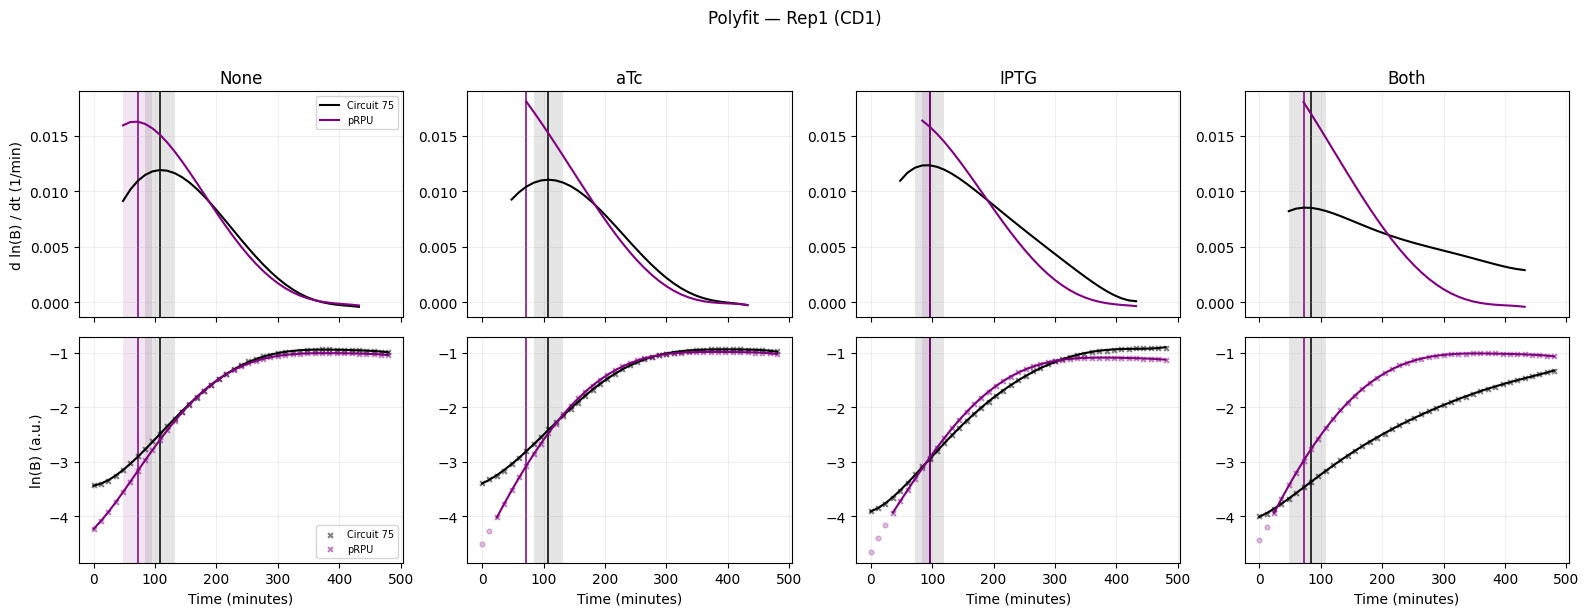

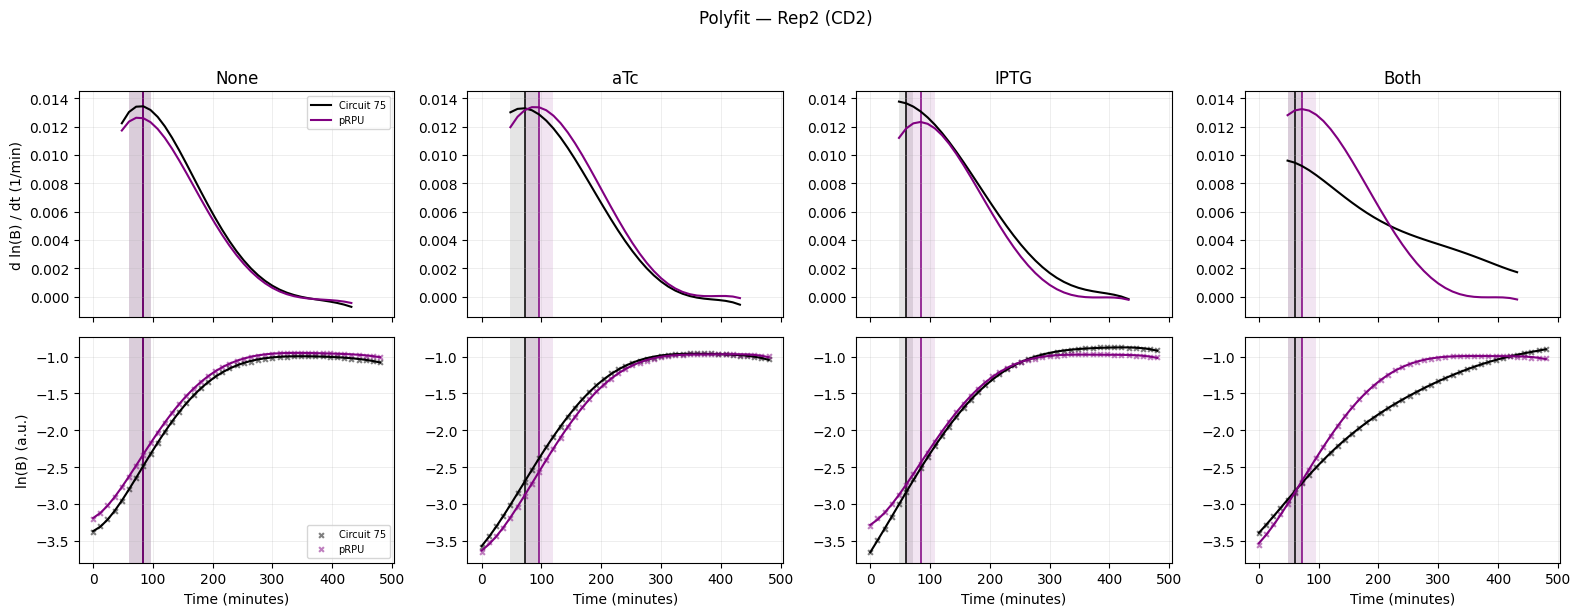

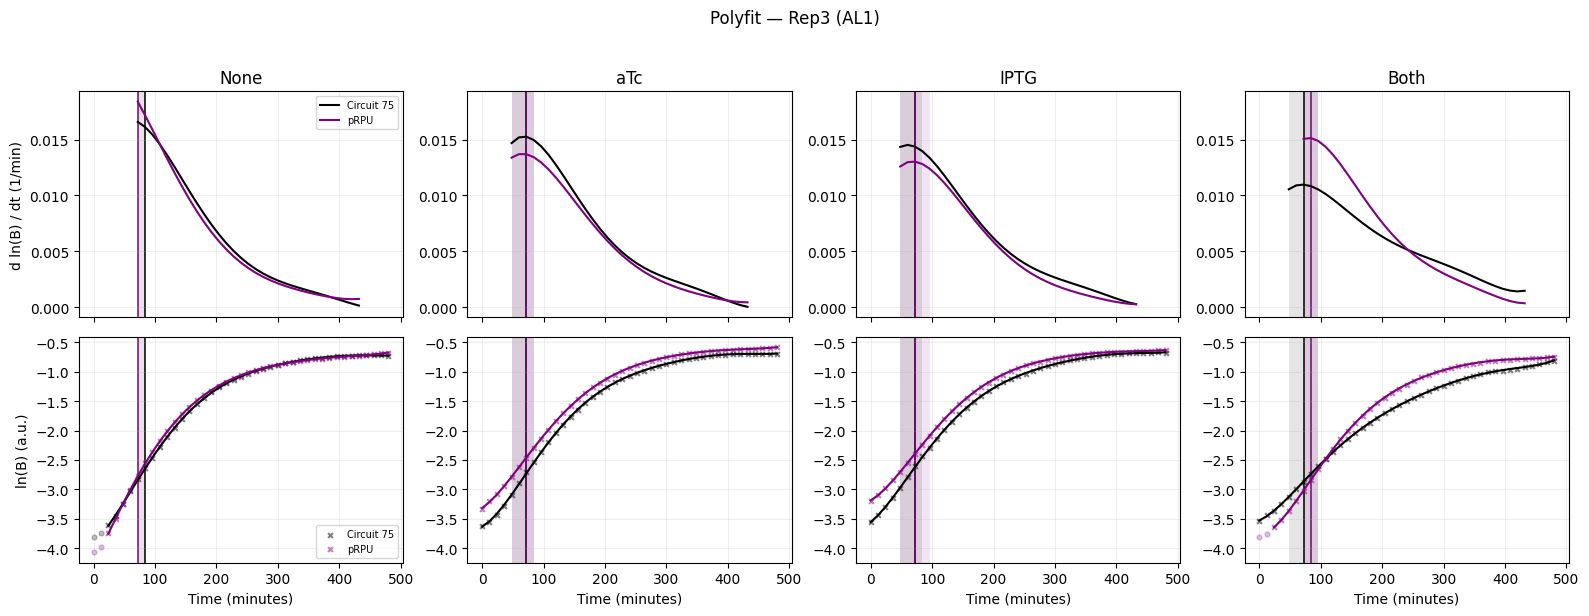

In [11]:
plot_growth_rate(gr_polyfit, "Polyfit", ln_od_fit=ln_od_polyfit)


## Method 2: SG

In [12]:
from scipy.signal import savgol_filter

def savgol_growth_rate(od, t_arr):
    """Savitzky-Golay deriv=1 on ln(OD), per contiguous valid segment."""
    growth_rate = np.full_like(od, np.nan, dtype=float)
    dt = float(t_arr[1] - t_arr[0])
    for well in range(od.shape[0]):
        ln_od = np.log(od[well])
        valid = np.isfinite(ln_od)
        # Longest contiguous finite run
        runs = np.flatnonzero(np.diff(np.r_[0, valid.astype(np.int8), 0])).reshape(-1, 2)
        if len(runs) == 0:
            continue
        first, stop = max(runs, key=lambda run: run[1] - run[0])
        if stop - first < SG_WINDOW:
            continue
        last = stop - 1
        deriv = savgol_filter(ln_od[first:last + 1], window_length=SG_WINDOW,
                              polyorder=SG_POLYORDER, deriv=1, delta=dt, mode="interp")
        growth_rate[well, first + SG_EDGE_EXCLUDE:last + 1 - SG_EDGE_EXCLUDE] = (
            deriv[SG_EDGE_EXCLUDE:len(deriv) - SG_EDGE_EXCLUDE])
    return growth_rate


In [ ]:
gr_sg = {}
for name in ALL_GROUPS:
    gr_sg[name] = {}
    for tag in TAGS:
        gr_sg[name][tag] = savgol_growth_rate(od_gmf[name][tag], t_minutes[tag])


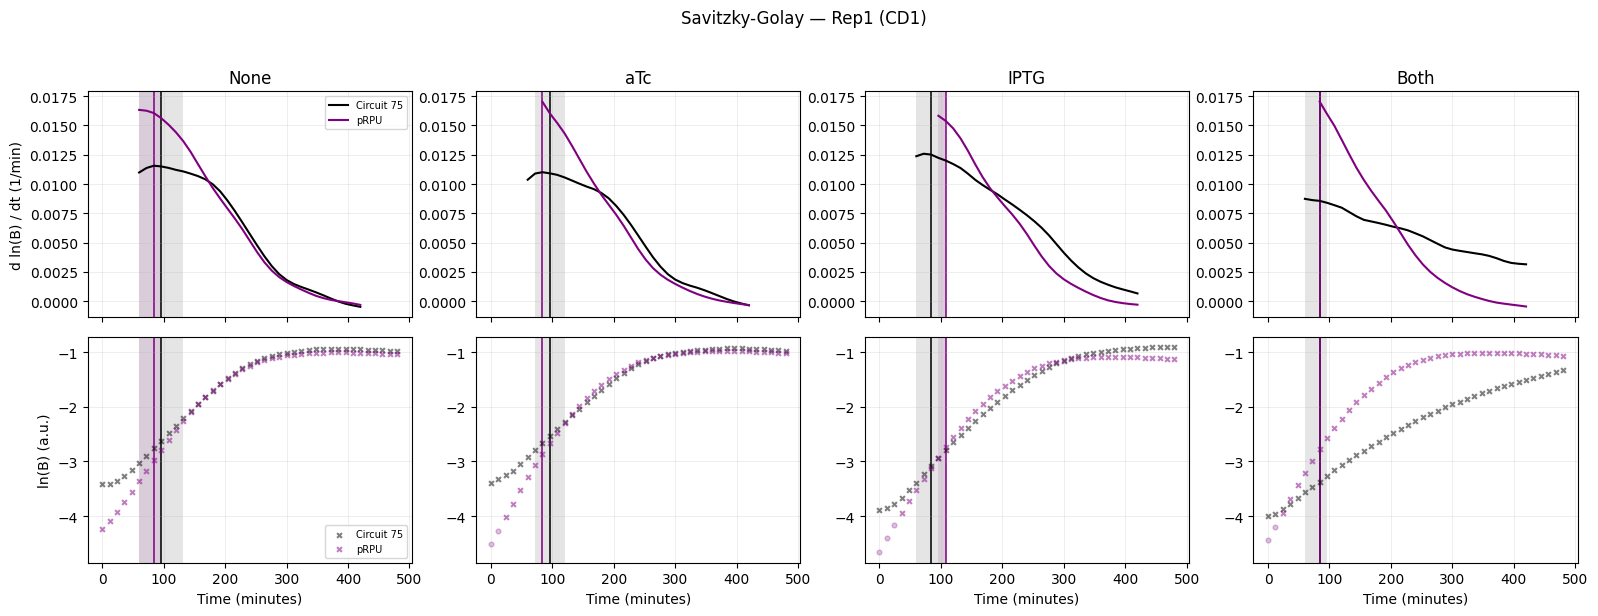

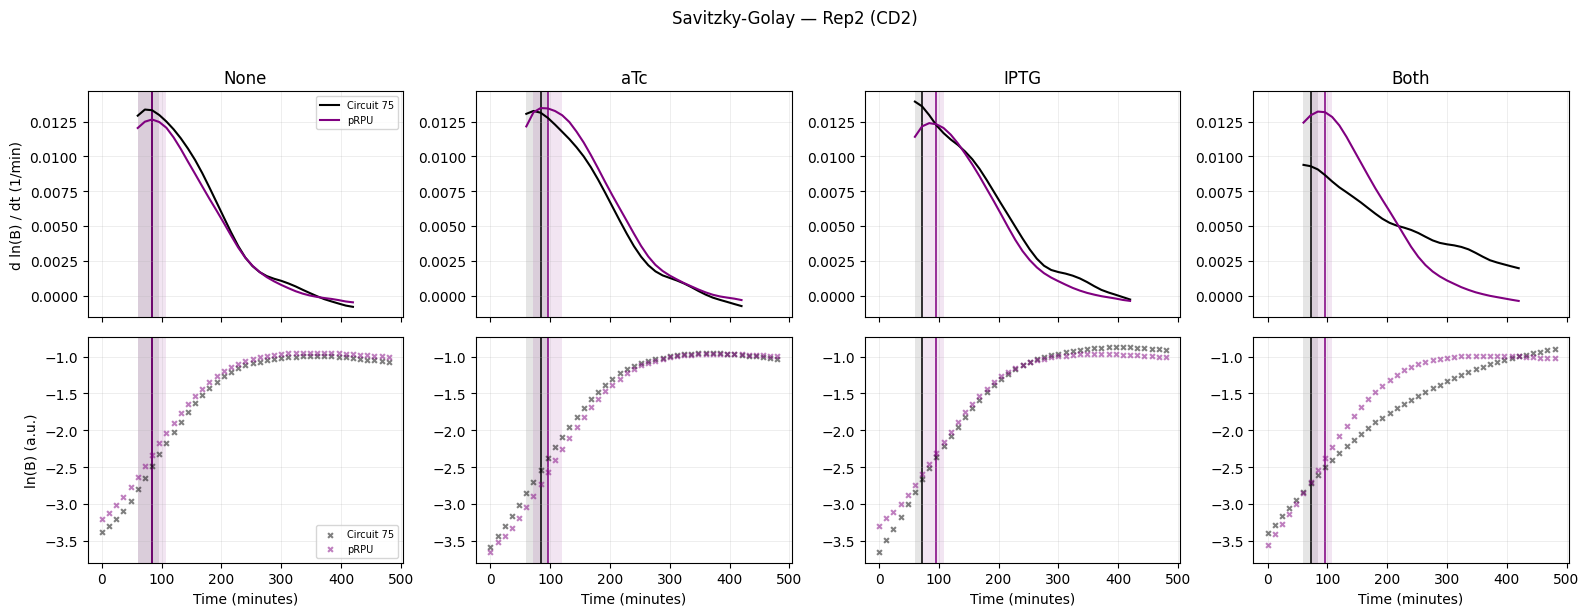

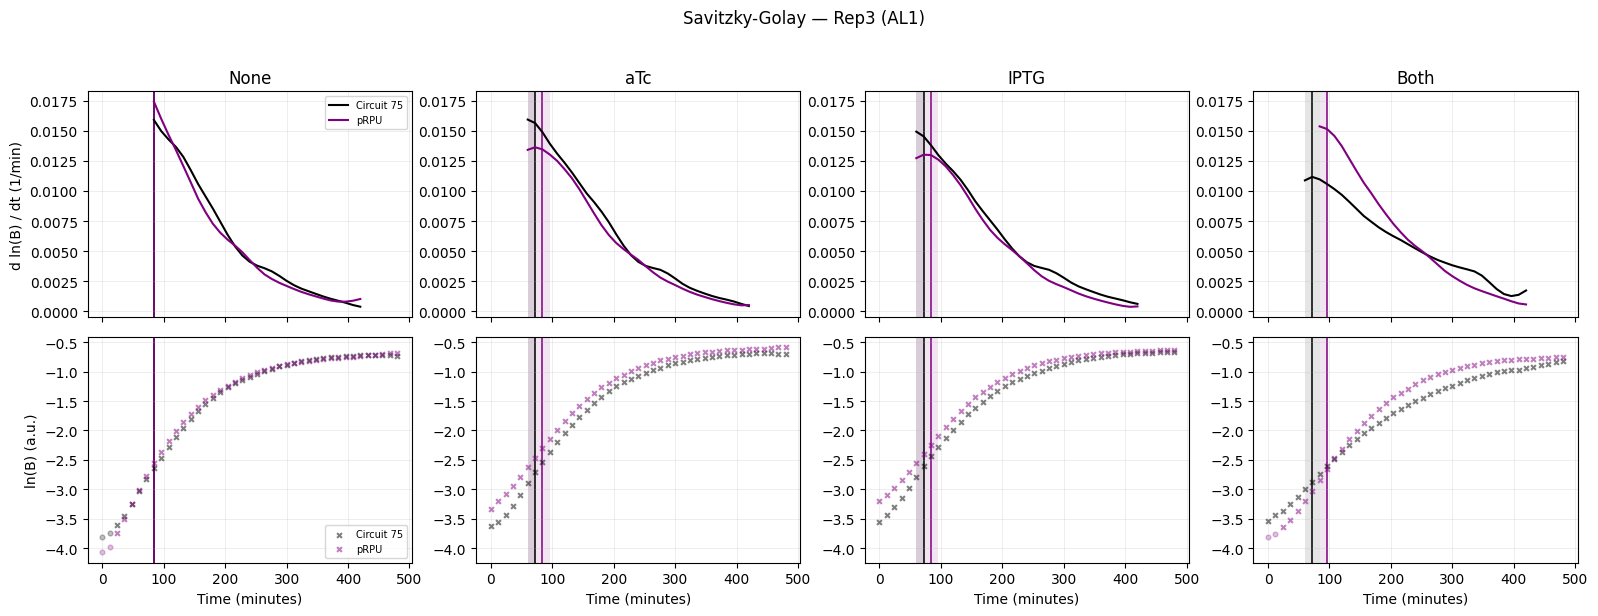

In [14]:
plot_growth_rate(gr_sg, "Savitzky-Golay")


## Method 3: Moving Window Linear (on Log)

In [15]:
# (GrowthRates, doi:10.1093/molbev/mst187)
WINDOW_SIZE = 5
# Timepoints at each end where the slope is not read
WINDOW_EDGE_EXCLUDE = 2


def moving_window_growth_rate(od, t_arr):
    """Slope of a WINDOW_SIZE-point linear fit of ln(OD) vs t, at each window centre."""
    growth_rate = np.full_like(od, np.nan, dtype=float)
    half = WINDOW_SIZE // 2
    for well in range(od.shape[0]):
        ln_od = np.log(od[well])
        for i in range(od.shape[-1] - WINDOW_SIZE + 1):
            window_y = ln_od[i:i + WINDOW_SIZE]
            if not np.isfinite(window_y).all():
                continue
            growth_rate[well, i + half] = np.polyfit(t_arr[i:i + WINDOW_SIZE], window_y, 1)[0]
        # in the fit, out of the peak search
        reported = np.flatnonzero(np.isfinite(growth_rate[well]))
        growth_rate[well, reported[:WINDOW_EDGE_EXCLUDE]] = np.nan
        growth_rate[well, reported[-WINDOW_EDGE_EXCLUDE:]] = np.nan
    return growth_rate


In [16]:
# Fed od_gmf, as the other two methods are
gr_window = {}
for name in ALL_GROUPS:
    gr_window[name] = {}
    for tag in TAGS:
        gr_window[name][tag] = moving_window_growth_rate(od_gmf[name][tag], t_minutes[tag])


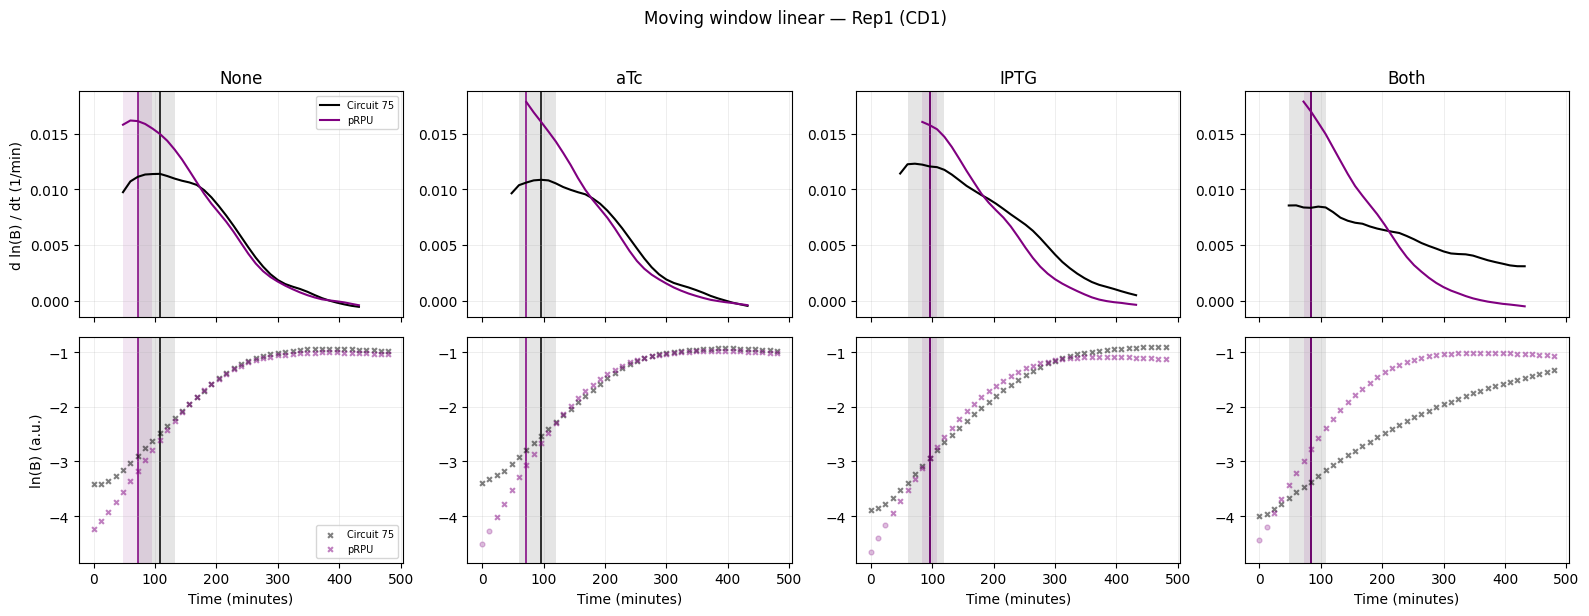

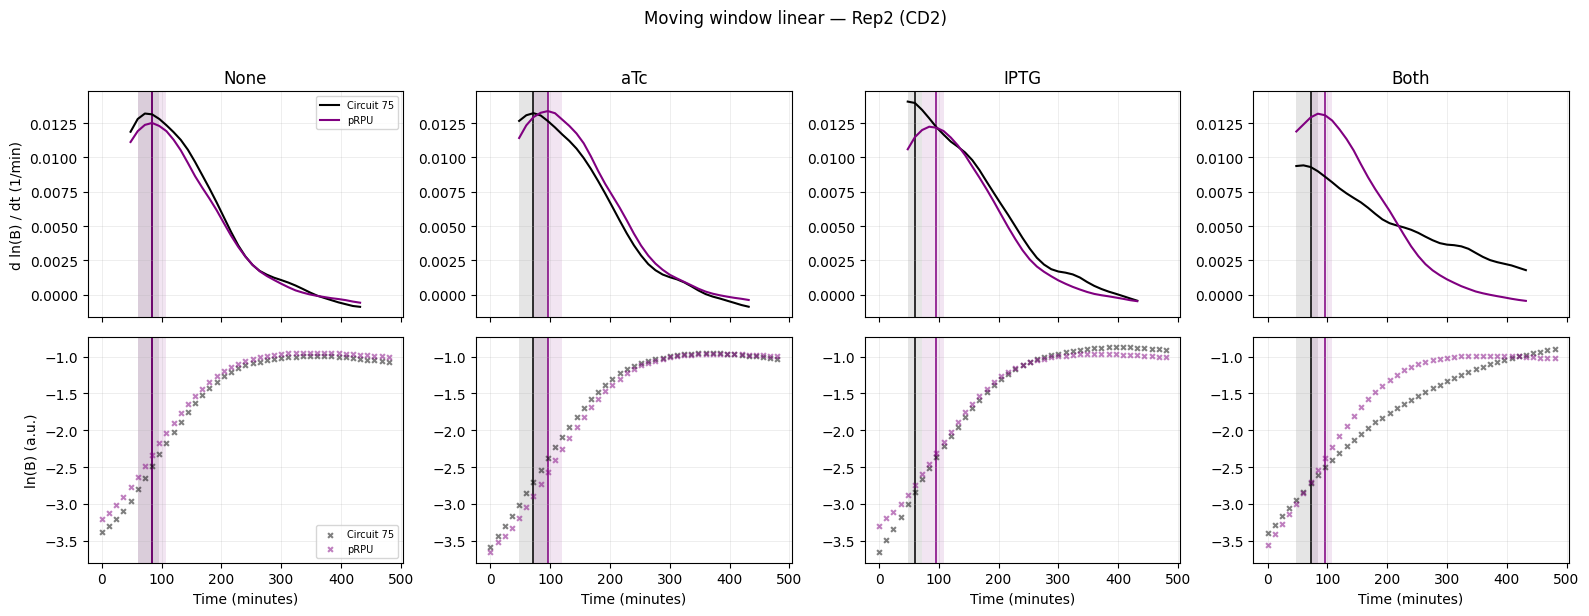

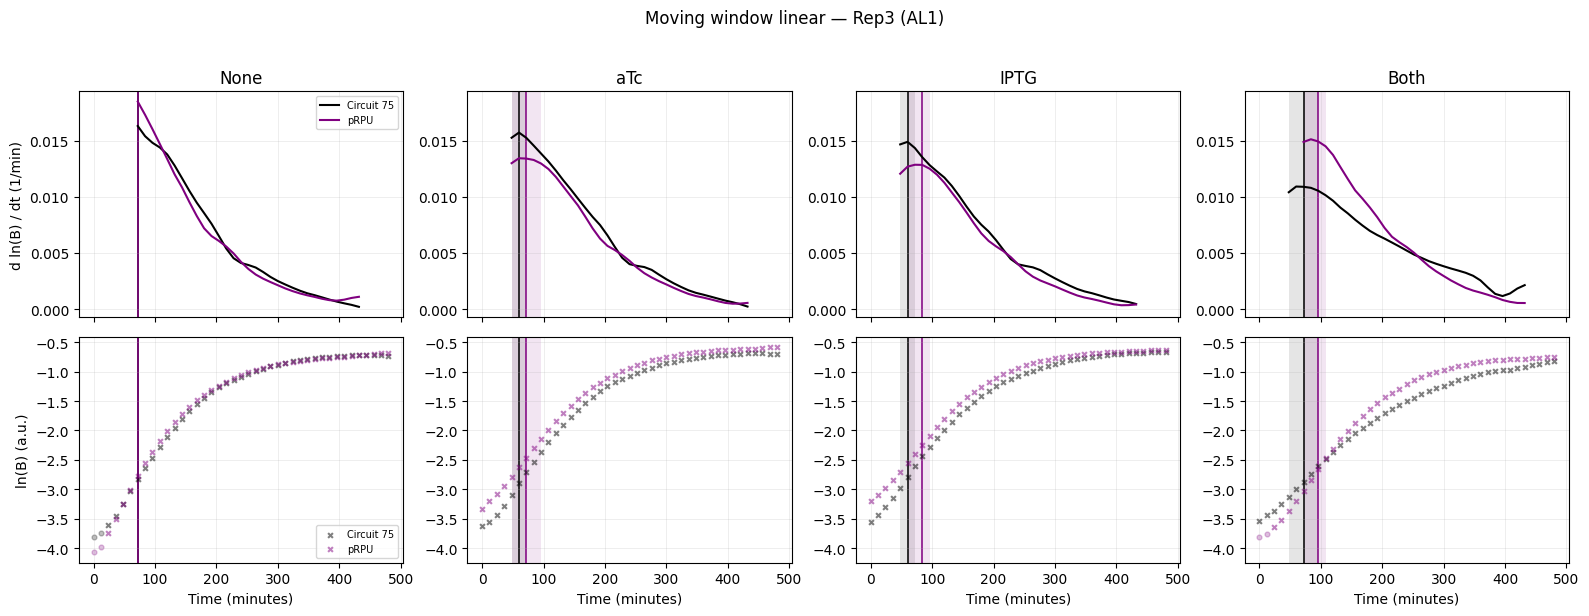

In [17]:
plot_growth_rate(gr_window, "Moving window linear")


# Method Comparison

In [18]:
# One row per (group, rep, condition), one column per method
import pandas as pd

def window_summary(growth_rate_series, biomass_series, t_arr, method):
    """Every window-derived quantity the CSV reports, for one method on one well."""
    window = exp_growth_window_indices(growth_rate_series)
    if window is None:
        first_index = last_index = mid_index = None
        mean_growth_rate = np.nan
        window_points = np.nan
    else:
        first_index, last_index = window
        mid_index = window_middle(first_index, last_index)
        mean_growth_rate = float(np.nanmean(growth_rate_series[first_index:last_index + 1]))
        window_points = last_index - first_index + 1

    def at(index, series, digits):
        return np.nan if index is None else round(float(series[index]), digits)

    return {f"mean_growth_rate_95pct_{method}": round(mean_growth_rate, 5),
            f"window_points_{method}": window_points,
            f"t_window_first_{method}": at(first_index, t_arr, 1),
            f"t_window_last_{method}": at(last_index, t_arr, 1),
            f"t_sampled_{method}": at(mid_index, t_arr, 1),
            f"growth_rate_at_sampled_{method}": at(mid_index, growth_rate_series, 5),
            f"biomass_at_sampled_{method}": at(mid_index, biomass_series, 5)}


records = []
for name in ALL_GROUPS:
    for rep in REPLICATES:
        tag = rep["tag"]
        for well in range(4):
            # the window mean, its width and the sampled point, per method
            windows = {}
            for method, growth_rate in (("polyfit", gr_polyfit), ("sg", gr_sg),
                                        ("window", gr_window)):
                windows.update(window_summary(
                    growth_rate[name][tag][well], od_gmf[name][tag][well],
                    t_minutes[tag], method))
            records.append({
                "Group": name, "Rep": rep["label"], "Condition": rep["cond_labels"][well],
                "max_growth_rate_polyfit":  round(peak_growth_rate(gr_polyfit[name][tag][well]), 5),
                "max_growth_rate_sg":       round(peak_growth_rate(gr_sg[name][tag][well]), 5),
                "max_growth_rate_window":   round(peak_growth_rate(gr_window[name][tag][well]), 5),
                # Per method: window mean rate, width, edges and sampled point
                **windows,
            })

growth_summary = pd.DataFrame(records)
# Read back with keep_default_na=False, na_values=[""]
growth_summary.to_csv(OUT_DIR / "analyse_pr_biomass.csv", index=False)
growth_summary


,Group,Rep,Condition,max_growth_rate_polyfit,max_growth_rate_sg,max_growth_rate_window,mean_growth_rate_95pct_polyfit,window_points_polyfit,t_window_first_polyfit,t_window_last_polyfit,...,t_sampled_sg,growth_rate_at_sampled_sg,biomass_at_sampled_sg,mean_growth_rate_95pct_window,window_points_window,t_window_first_window,t_window_last_window,t_sampled_window,growth_rate_at_sampled_window,biomass_at_sampled_window
0,Circuit 1,CD1,None,0.00963,0.00932,0.00924,0.00949,5.0,96.0,144.0,...,108.0,0.00925,0.12283,0.00907,6.0,84.0,144.0,120.0,0.00910,0.13720
1,Circuit 1,CD1,aTc,0.00925,0.00900,0.00900,0.00914,5.0,108.0,156.0,...,120.0,0.00900,0.11713,0.00883,5.0,96.0,144.0,120.0,0.00900,0.11713
2,Circuit 1,CD1,IPTG,0.01003,0.00994,0.00986,0.00983,6.0,84.0,144.0,...,108.0,0.00987,0.11527,0.00969,5.0,84.0,132.0,108.0,0.00986,0.11527
3,Circuit 1,CD1,Both,0.01202,0.01210,0.01200,0.01179,6.0,84.0,144.0,...,108.0,0.01205,0.07650,0.01175,5.0,84.0,132.0,108.0,0.01200,0.07650
4,Circuit 1,CD2,None,0.01116,0.01125,0.01105,0.01100,5.0,72.0,120.0,...,84.0,0.01121,0.08943,0.01085,5.0,60.0,108.0,84.0,0.01105,0.08943
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1135,WT,CD2,Both,0.01881,0.01717,0.01896,0.01881,1.0,48.0,48.0,...,60.0,0.01717,0.07483,0.01896,1.0,48.0,48.0,48.0,0.01896,0.06082
1136,WT,AL1,None,0.01657,0.01615,0.01599,0.01638,3.0,60.0,84.0,...,84.0,0.01569,0.06929,0.01572,3.0,60.0,84.0,72.0,0.01580,0.05733
1137,WT,AL1,aTc,0.01704,0.01638,0.01658,0.01689,2.0,72.0,84.0,...,84.0,0.01638,0.06239,0.01621,2.0,72.0,84.0,84.0,0.01584,0.06239
1138,WT,AL1,IPTG,0.01691,0.01663,0.01678,0.01664,3.0,60.0,84.0,...,84.0,0.01580,0.07286,0.01648,2.0,60.0,72.0,72.0,0.01618,0.05997


# All Circuits


In [19]:
def plot_circuit_page(group, growth_rate, title, ln_od_fit=None):
    """One PDF page for a group: three (growth rate, ln(B)) row-pairs, one per replicate."""
    page_groups = {name: ALL_GROUPS[name] for name in (group, "pRPU")}

    figure, axes = plt.subplots(6, 4, figsize=(16, 18), sharex=True)
    for row in (0, 2, 4):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])
    for row in (1, 3, 5):
        for ax in axes[row, 1:]:
            ax.sharey(axes[row, 0])

    for rep_i, rep in enumerate(REPLICATES):
        tag = rep["tag"]
        for well in range(4):
            condition = rep["cond_labels"][well]
            ax_gr, ax_lod = axes[2 * rep_i, well], axes[2 * rep_i + 1, well]
            for name, (wells, colour) in page_groups.items():
                # Exponential-growth window
                if np.isfinite(growth_rate[name][tag][well]).any():
                    start_i, end_i = transform.exp_growth_window(
                        growth_rate[name][tag][well], threshold=EXP_GROWTH_PHASE_THRESHOLD)
                    for ax in (ax_gr, ax_lod):
                        ax.axvspan(t_minutes[tag][start_i], t_minutes[tag][end_i],
                                   color=colour, alpha=0.10, zorder=0, linewidth=0)
                        # Sampled point
                        ax.axvline(t_minutes[tag][window_middle(start_i, end_i)], color=colour,
                                   ls="-", lw=1.4, alpha=0.8, zorder=0.5)

                # growth rate
                ax_gr.plot(t_minutes[tag], growth_rate[name][tag][well],
                           color=colour, lw=1.5, label=name)

                # ln(B)
                ax_lod.plot(t_minutes[tag], np.log(od_gmf[name][tag][well]),
                            "x", color=colour, ms=3.5, alpha=0.5, zorder=2, label=name)
                if ln_od_fit is not None:
                    ax_lod.plot(t_minutes[tag], ln_od_fit[name][tag][well],
                                color=colour, lw=1.5, zorder=3)
                with np.errstate(invalid="ignore"):
                    ax_lod.plot(t_minutes[tag], np.log(od_excluded[name][tag][well]),
                                "o", color=colour, ms=3.5, alpha=0.25, zorder=1)

            if rep_i == 0:
                ax_gr.set_title(condition)
            if rep_i == len(REPLICATES) - 1:
                ax_lod.set_xlabel("Time (minutes)")
            for ax in (ax_gr, ax_lod):
                ax.grid(True, alpha=0.3, linewidth=0.5)
            if well == 0:
                ax_gr.set_ylabel(f"{tag} ({rep['label']})\nd ln(B) / dt (1/min)")
                ax_lod.set_ylabel("ln(B) (a.u.)")
                ax_gr.legend(fontsize=7)

    figure.suptitle(f"{group} — {title}", y=0.995)
    figure.subplots_adjust(left=0.05, right=0.99, top=0.96, bottom=0.03,
                           hspace=0.15, wspace=0.12)
    return figure


In [ ]:
import time
from matplotlib.backends.backend_pdf import PdfPages


# Every circuit gets a page, including pL2
PDF_PAGE_GROUPS = [f"Circuit {circuit}" for circuit in range(1, 93)] + ["pL2", "WT"]

# (file suffix, growth rate, title, ln(B) fit)
METHODS = [
    ("polyfit", gr_polyfit, "Polyfit", ln_od_polyfit),
    ("sg",      gr_sg,      "Savitzky-Golay", None),
    ("mwindow", gr_window,  "Moving window linear", None),
]

if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the per-method circuit PDFs")
else:
    for suffix, growth_rate, title, ln_od_fit in METHODS:
        path = OUT_DIR / f"analyse_pr_biomass_{suffix}.pdf"
        started = time.perf_counter()
        with PdfPages(path) as pdf:
            for group in PDF_PAGE_GROUPS:
                figure = plot_circuit_page(group, growth_rate, title,
                                           ln_od_fit=ln_od_fit)
                pdf.savefig(figure, dpi=PDF_DPI)
                plt.close(figure)
        print(f"{path}: 92 pages, {time.perf_counter() - started:.0f}s, "
              f"{path.stat().st_size / 1e6:.1f} MB")


out/analyse_pr_biomass_polyfit.pdf: 92 pages, 119s, 4.8 MB
out/analyse_pr_biomass_sg.pdf: 92 pages, 141s, 4.0 MB


In [ ]:
def plot_bg_correction_page(name, wells, colour):
    """One page: raw ln(OD) against corrected ln(B), replicates down, conditions across."""
    figure, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)

    for rep_i, rep in enumerate(REPLICATES):
        tag = rep["tag"]
        rows, cols = zip(*wells)
        raw = od_raw[tag][list(rows), list(cols), :].astype(float)
        # Corrected is smoothed, raw is not
        corrected_all, above_all = biomass_and_floor(raw, POOLED_BLANK[tag],
                                                     DETECTION_THRESHOLD[tag])
        corrected = np.where(above_all, corrected_all, np.nan)
        corrected_excluded = np.where(above_all, np.nan, corrected_all)

        for well in range(4):
            ax = axes[rep_i, well]
            above = above_all[well]
            with np.errstate(invalid="ignore"):
                # raw
                ax.plot(t_minutes[tag][above], np.log(raw[well][above]),
                        "x", color=colour, ms=4, alpha=0.25, zorder=2)
                ax.plot(t_minutes[tag][~above], np.log(raw[well][~above]),
                        "o", color=colour, ms=3.5, alpha=0.25, zorder=2)
                # blank-corrected
                ax.plot(t_minutes[tag], np.log(corrected[well]),
                        "x", color=colour, ms=4, alpha=1.0, zorder=3)
                ax.plot(t_minutes[tag], np.log(corrected_excluded[well]),
                        "o", color=colour, ms=3.5, alpha=0.5, zorder=3)

            ax.grid(True, alpha=0.3, linewidth=0.5, which="both")
            if rep_i == 0:
                ax.set_title(rep["cond_labels"][well])
            if rep_i == len(REPLICATES) - 1:
                ax.set_xlabel("Time (minutes)")
            if well == 0:
                ax.set_ylabel(f"ln(OD) raw, ln(B) corrected\n{tag} ({rep['label']})")

    figure.suptitle(f"Raw ln(OD) vs corrected ln(B) — {name}", y=0.995)
    figure.subplots_adjust(left=0.05, right=0.99, top=0.93, bottom=0.07,
                           hspace=0.12, wspace=0.10)
    return figure


In [ ]:
# Controls first, then every circuit
BG_PAGES = [
    ("pRPU", WELLS["pRPU"], "purple"),
    ("pL2",  WELLS["pL2"],  "orange"),
    ("WT",   WELLS["wt"],   "navy"),
] + [(f"Circuit {circuit}", WELLS["circuits"][circuit], "black")
     for circuit in range(1, 93)]

if not GENERATE_PDF:
    print("GENERATE_PDF is False: skipping the background-correction PDF")
else:
    path = OUT_DIR / "analyse_pr_biomass_bg_correction.pdf"
    started = time.perf_counter()
    with PdfPages(path) as pdf:
        for name, wells, colour in BG_PAGES:
            figure = plot_bg_correction_page(name, wells, colour)
            pdf.savefig(figure, dpi=PDF_DPI)
            plt.close(figure)
    print(f"{path}: {len(BG_PAGES)} pages, {time.perf_counter() - started:.0f}s, "
          f"{path.stat().st_size / 1e6:.1f} MB")


/tmp/ipykernel_2892982/4286541328.py:27: RuntimeWarning: divide by zero encountered in log
  ax.plot(t_minutes[tag], np.log(corrected_excluded[well]),


out/analyse_pr_biomass_bg_correction.pdf: 95 pages, 67s, 2.2 MB
